# Solution: Mission 02 — House Price Feature Lab

This notebook is one possible solution. Try the mission yourself before you read it.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent.parent / "tools"))
import datasets

RNG = 42

from sklearn.model_selection import train_test_split

ames = datasets.ames()
train, test = train_test_split(ames, test_size=0.2, random_state=RNG)        # keep `test` untouched until Task 6
print(train.shape, test.shape)

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

cv = KFold(5, shuffle=True, random_state=RNG)
QUALITY = ["Very_Poor", "Poor", "Fair", "Below_Average", "Average", "Above_Average", "Good", "Very_Good", "Excellent", "Very_Excellent"]
GRADE = ["No_Basement", "No_Garage", "No_Fireplace", "No_Pool", "Poor", "Fair", "Typical", "Good", "Excellent"]
ORDERED = {"Overall_Qual": QUALITY, "Overall_Cond": QUALITY,
           **{c: GRADE for c in ["Exter_Qual", "Exter_Cond", "Bsmt_Qual", "Bsmt_Cond", "Heating_QC", "Kitchen_Qual",
                                 "Fireplace_Qu", "Garage_Qual", "Garage_Cond"]}}
steps = []

def score(name, model, X, y):
    rmse = -cross_val_score(model, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()
    steps.append({"step": name, "CV RMSE (USD)": round(rmse)})
    print(f"{name:<50} {rmse:10,.0f}")

(2344, 81) (586, 81)


## Task 1: Baseline

In [2]:
y = train["Sale_Price"]
num_cols = train.drop(columns=["Sale_Price", "Longitude", "Latitude"]).select_dtypes("number").columns.tolist()
score("1 baseline: Ridge on numeric columns", make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), train[num_cols], y)

1 baseline: Ridge on numeric columns                   39,605


## Task 2: Cleaning Rules

In [3]:
print("Lot_Frontage == 0:", (train["Lot_Frontage"] == 0).sum(), "| houses > 4,000 sq ft:", (train["Gr_Liv_Area"] > 4000).sum())

class Clean(BaseEstimator, TransformerMixin):
    """Lot_Frontage 0 -> missing, filled with the training median of the neighbourhood."""
    def fit(self, X, y=None):
        lf = X["Lot_Frontage"].replace(0, np.nan)
        self.by_hood_ = lf.groupby(X["Neighborhood"]).median()
        self.overall_ = float(lf.median())
        return self
    def transform(self, X):
        X = X.copy()
        lf = X["Lot_Frontage"].replace(0, np.nan)
        X["Lot_Frontage"] = lf.fillna(X["Neighborhood"].map(self.by_hood_)).fillna(self.overall_)
        return X

keep = train["Gr_Liv_Area"] <= 4000                                  # documented rule: Partial sales of huge houses
tr = train[keep]
score("2 + cleaning (frontage, drop > 4,000 sq ft)", make_pipeline(Clean(), ColumnTransformer([("n", StandardScaler(), num_cols)]),
                                                                  RidgeCV(alphas=np.logspace(-2, 3, 30))), tr, tr["Sale_Price"])

Lot_Frontage == 0: 393 | houses > 4,000 sq ft: 4


2 + cleaning (frontage, drop > 4,000 sq ft)            31,036


## Tasks 3–4: Encoding, Domain Features, Log Target

In [4]:
class Domain(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        X["total_sf"] = X["Gr_Liv_Area"] + X["Total_Bsmt_SF"]
        X["age_at_sale"] = X["Year_Sold"] - X["Year_Built"]
        X["years_since_remodel"] = X["Year_Sold"] - X["Year_Remod_Add"]
        X["total_baths"] = X["Full_Bath"] + 0.5 * X["Half_Bath"] + X["Bsmt_Full_Bath"] + 0.5 * X["Bsmt_Half_Bath"]
        X["porch_sf"] = X[["Wood_Deck_SF", "Open_Porch_SF", "Enclosed_Porch", "Screen_Porch", "Three_season_porch"]].sum(axis=1)
        X["log_lot_area"] = np.log(X["Lot_Area"])
        return X

DOMAIN = ["total_sf", "age_at_sale", "years_since_remodel", "total_baths", "porch_sf", "log_lot_area"]
ordered_cols = list(ORDERED)
nominal = [c for c in train.select_dtypes(include="str").columns if c not in ordered_cols]

def full_pipeline(with_domain=True, log_target=True, nominal_cols=nominal):
    cols_num = num_cols + (DOMAIN if with_domain else [])
    pre = ColumnTransformer([
        ("num", StandardScaler(), cols_num),
        ("ord", make_pipeline(OrdinalEncoder(categories=[ORDERED[c] for c in ordered_cols], handle_unknown="use_encoded_value",
                                             unknown_value=-1), StandardScaler()), ordered_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore", min_frequency=10), nominal_cols),
    ])
    steps_ = [Clean()] + ([Domain()] if with_domain else []) + [pre, RidgeCV(alphas=np.logspace(-2, 3, 30))]
    model = make_pipeline(*steps_)
    return TransformedTargetRegressor(model, func=np.log, inverse_func=np.exp) if log_target else model

score("3 + ordered grades + one-hot categories", full_pipeline(with_domain=False, log_target=False), tr, tr["Sale_Price"])
score("4a + log(price) target", full_pipeline(with_domain=False, log_target=True), tr, tr["Sale_Price"])
score("4b + six domain features", full_pipeline(with_domain=True, log_target=True), tr, tr["Sale_Price"])

3 + ordered grades + one-hot categories                22,553


4a + log(price) target                                 19,549


4b + six domain features                               19,136


## Task 5: Step Table

                                       step  CV RMSE (USD)  change_vs_previous_%
       1 baseline: Ridge on numeric columns          39605                   NaN
2 + cleaning (frontage, drop > 4,000 sq ft)          31036                 -21.6
    3 + ordered grades + one-hot categories          22553                 -27.3
                     4a + log(price) target          19549                 -13.3
                   4b + six domain features          19136                  -2.1


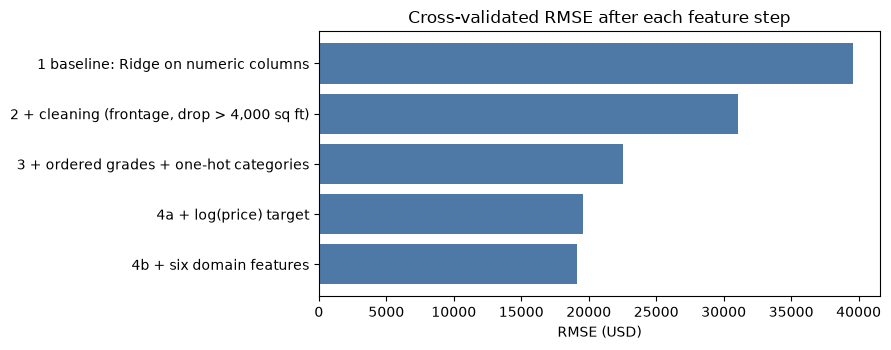

In [5]:
table = pd.DataFrame(steps)
table["change_vs_previous_%"] = (100 * table["CV RMSE (USD)"].pct_change()).round(1)
print(table.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(table["step"][::-1], table["CV RMSE (USD)"][::-1], color="#4E79A7")
ax.set(title="Cross-validated RMSE after each feature step", xlabel="RMSE (USD)")
plt.tight_layout()
plt.show()

Note: from step 2 on, the CV runs on training houses up to 4,000 sq ft, so steps 1 and 2 are not measured on exactly the same rows. The test set in Task 6 uses all houses, so the final number is comparable with the real use case.

## Task 6: Final Test

The test set contains one very large "Partial" sale (an unfinished house above 4,000 sq ft). The model was trained without such houses, and this single house dominates the squared error on all houses; the cell therefore also reports the error on normal houses. In production, listings above 4,000 sq ft would need a separate rule or a human check.

test RMSE: 39,892 USD on all 586 houses | 18,717 USD on houses up to 4,000 sq ft


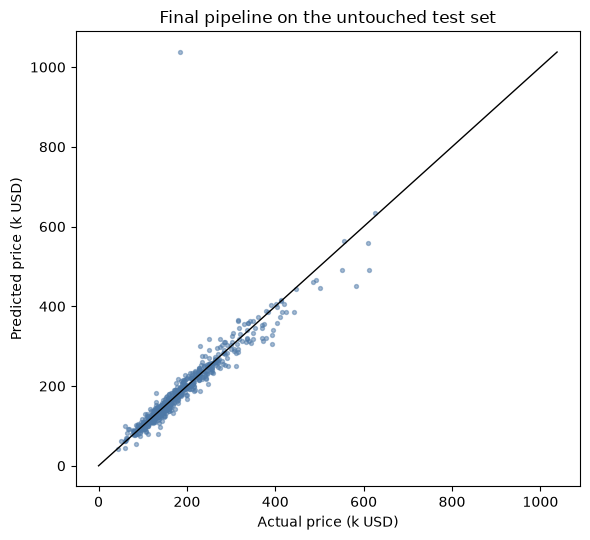

In [6]:
final = full_pipeline(with_domain=True, log_target=True).fit(tr, tr["Sale_Price"])
pred = final.predict(test)
rmse_all = np.sqrt(np.mean((pred - test["Sale_Price"]) ** 2))
normal = test["Gr_Liv_Area"] <= 4000
rmse_norm = np.sqrt(np.mean((pred[normal] - test.loc[normal, "Sale_Price"]) ** 2))
print(f"test RMSE: {rmse_all:,.0f} USD on all {len(test)} houses | {rmse_norm:,.0f} USD on houses up to 4,000 sq ft")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(test["Sale_Price"] / 1000, pred / 1000, s=8, alpha=0.5, color="#4E79A7")
lim = [0, max(test["Sale_Price"].max(), pred.max()) / 1000]
ax.plot(lim, lim, color="black", lw=1)
ax.set(xlabel="Actual price (k USD)", ylabel="Predicted price (k USD)", title="Final pipeline on the untouched test set")
plt.tight_layout()
plt.show()